In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
    
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [2]:
from pyabs.core.basis import ABSBasisConfig, build_abs_basis
from pyabs.core.matrix import build_abs_matrix
from pyabs.core.wake import ThetaWake, WakeScale
from pyabs.core.chromaticity import ChromaticScale
from pyabs.solvers.eigensolvers import solve_eigenvalues, scan_over_w
from pyabs.solvers.systemsolvers import solve_system

In [ ]:
%%time
from tqdm.notebook import tqdm
resolution = 200
n_max = 500
n_modes = 2*n_max + 1
qmax = 50
wmax = 100
ximax = -10
xistep = 1
qrange = np.linspace(0.0, qmax, num=resolution)
xirange = np.linspace(0.0, ximax, num=xistep)
wrange = np.linspace(0.0, wmax, num=resolution)
imeig_max = np.empty((resolution, resolution), dtype=float)
log_kmax = np.empty((resolution, resolution), dtype=float)


with tqdm(total=resolution * resolution, desc="Solving eigenvalues") as pbar:
    for i, q in enumerate(qrange):
        basis = build_abs_basis(np, ABSBasisConfig(n_max=n_max, q=q))
        for j, w in enumerate(wrange):
            theta_wake = ThetaWake(W0=1)
            matrix = build_abs_matrix(basis, wake_model=theta_wake, scale=WakeScale(w=w), xi=ChromaticScale(xi=1.0))
            solution = solve_system(matrix, A0=1)
            log_kmax[j][i] = np.log(np.max(solution.compute_amplification_factors()))
            imeig_max[j][i] = np.max(np.array(np.abs(solve_eigenvalues(matrix).imag))) 
            pbar.update(1)
        pbar.set_postfix(q=f"{q:.1f}")

rows, cols = np.meshgrid(np.arange(resolution), np.arange(resolution), indexing='ij')
df_matrix = pd.DataFrame({
    'source': 'matrix',
    'row': rows.ravel(),
    'col': cols.ravel(),
    'value': imeig_max.ravel()
})

# Arrays as row/value (col left as NaN)
df_arr1 = pd.DataFrame({'source': 'q', 'row': np.arange(resolution), 'col': np.nan, 'value': qrange})
df_arr2 = pd.DataFrame({'source': 'w', 'row': np.arange(resolution), 'col': np.nan, 'value': wrange})

df_all = pd.concat([df_matrix, df_arr1, df_arr2], ignore_index=True)
#df_all.to_csv(f'../../data/{n_modes}modes_{qmax}qmax_{wmax}wmax_{resolution}reso.csv', index=False)

Solving eigenvalues:   0%|          | 0/40000 [00:00<?, ?it/s]

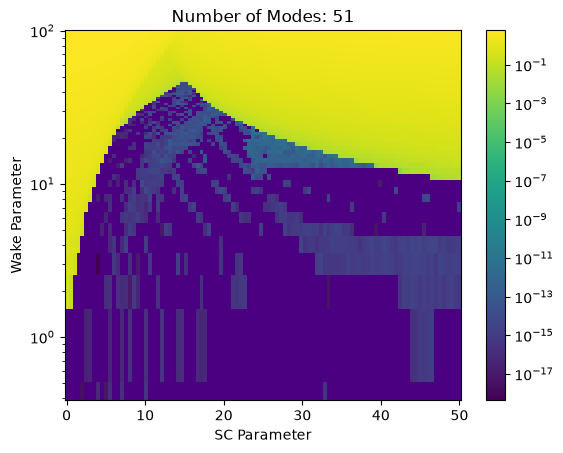

In [82]:
fig, ax = plt.subplots()
cmap = plt.cm.viridis.copy()
cmap.set_bad('indigo')
pcm = ax.pcolormesh(qrange, wrange, imeig_max, norm='log', cmap=cmap)
ax.set_yscale('log')
ax.set_xlabel('SC Parameter')
ax.set_ylabel('Wake Parameter')
plt.title(f"Number of Modes: {2*n_max+1}")
plt.colorbar(pcm, ax=ax)
#plt.savefig("../../plots/tcmi_paramscan_theta")
plt.show()

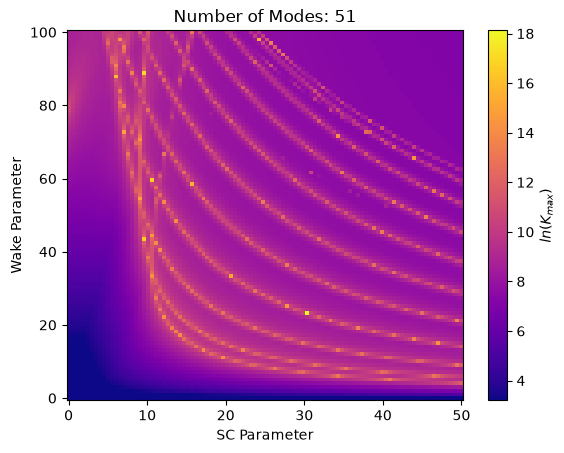

In [83]:
fig, ax = plt.subplots()

#pcm = ax.pcolormesh(qrange, wrange, log_kmax, norm=mcolors.Normalize(vmin=7, vmax=19), cmap='plasma')
pcm = ax.pcolormesh(qrange, wrange, log_kmax, norm='linear', cmap='plasma')
ax.set_yscale('linear')
ax.set_xlabel('SC Parameter')
ax.set_ylabel('Wake Parameter')
plt.title(f"Number of Modes: {2*n_max+1}")
plt.colorbar(pcm, ax=ax, label = rf"$ln(K_{{max}})$")
plt.savefig(f"../../plots/kmax_0p5xi_51modes")
plt.show()